# 1. Data Understanding

**Projeto:** Classificação de Ataques de Cibersegurança.

Objetivo: explorar a estrutura, a qualidade e as categorias do dataset antes de preparar os dados.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

paths = [Path("dataset/raw/Attack_Dataset.csv"), Path("../dataset/raw/Attack_Dataset.csv")]
path = next((p for p in paths if p.exists()), None)
if path is None:
    raise FileNotFoundError("Dataset não encontrado. Abre o projeto na pasta correta.")
df = pd.read_csv(path)
df.columns = df.columns.str.strip()
print("Dimensões:", df.shape)
display(df.head())


Dimensões: (14133, 16)


,ID,Title,Category,Attack Type,Scenario Description,Tools Used,Attack Steps,Target Type,Vulnerability,MITRE Technique,Impact,Detection Method,Solution,Tags,Source,Unnamed: 15
0,1,Authentication Bypass via SQL Injection,Mobile Security,SQL Injection (SQLi),A login form fails to validate or sanitize inp...,"Browser, Burp Suite, SQLMap",1. Reconnaissance: Find a login form on the we...,"Web Login Portals (e.g., banking, admin dashbo...",Unsanitized input fields in SQL queries,"T1078 (Valid Accounts), T1190 (Exploit Public-...","Full account takeover, data theft, privilege e...","Web server logs, anomaly detection (e.g., logi...","Use prepared statements, Sanitize inputs, Limi...","SQLi, Authentication Bypass, Web Security, OWA...","OWASP, MITRE ATT&CK, DVWA",NaN
1,2,Union-Based SQL Injection,AI Agents & LLM Exploits,SQL Injection,This attack occurs when a hacker uses the SQL ...,"SQLMap, Burp Suite, Havij, Browser Developer T...",1. Identify User Input Points: Attacker finds ...,"Web Applications, Login Pages, Search Forms",Improperly filtered input fields that allow SQ...,T1190 – Exploit Public-Facing Application,"Data leakage, Credential theft, Account takeov...",Web Application Firewalls (WAF)Log AnalysisInp...,Use parameterized queries (Prepared Statements...,#SQLInjection #WebSecurity #UnionAttack #OWASP...,"OWASP, MITRE ATT&CK, Acunetix, PortSwigger Web...",NaN
2,3,Error-Based SQL Injection,AI Agents & LLM Exploits,SQL Injection,This attack occurs when an attacker intentiona...,"SQLMap, Burp Suite, Manual Browser Testing, Havij",1. Identify Input Points:Attacker finds a fiel...,"Web Applications, Login Forms, URL Parameters,...",Error message exposure due to lack of input va...,T1190 – Exploit Public-Facing Application,"Information disclosure, Database structure exp...",Review and monitor error logsEnable generic er...,Turn off detailed error messages in production...,#SQLInjection #ErrorLeakage #WebAppSecurity #O...,"OWASP, MITRE ATT&CK, Acunetix, PortSwigger Web...",NaN
3,4,Blind SQL Injection,AI Agents & LLM Exploits,SQL Injection,"In Blind SQL Injection, the attacker doesn’t s...","SQLMap, Burp Suite, sqlninja, Manual Browser T...",1. Find a User Input Point:Attacker finds a pl...,"Web Applications, Login Pages, Search Fields, ...","No error messages, but user input is still pas...",T1190 – Exploit Public-Facing Application,Slow and stealthy data theftFull database comp...,Monitor for slow and repetitive requestsAnalyz...,Use parameterized queries (prepared statements...,#BlindSQLi #TimeBasedSQLi #WebAppSecurity #OWA...,"OWASP, MITRE ATT&CK, Acunetix, PortSwigger, SQ...",NaN
4,5,Second-Order SQL Injection,AI Agents & LLM Exploits,SQL Injection,"In a Second-Order SQL Injection, the attacker ...","Burp Suite, SQLMap, Postman, Browser Dev Tools...",1. Identify Stored Input Fields:The attacker l...,"Web Applications, User Registration Forms, Pro...",Trusting previously stored unvalidated data in...,T1505.003 – SQL Injection,Delayed data theftUnexpected system behaviorSe...,Log monitoring for delayed query failuresTrack...,Sanitize and validate inputs both at entry and...,#SecondOrderSQLi #DelayedInjection #StoredInje...,"OWASP, MITRE ATT&CK, PortSwigger Academy, Acun...",NaN


## 2. Qualidade dos dados

Verificamos os tipos de dados, os valores em falta e os duplicados.

In [2]:
display(df.dtypes.to_frame("Tipo"))
display(df.isna().sum().to_frame("Valores nulos"))
print("Linhas duplicadas:", df.duplicated().sum())


,Tipo
ID,int64
Title,str
Category,str
Attack Type,str
Scenario Description,str
Tools Used,str
Attack Steps,str
Target Type,str
Vulnerability,str
MITRE Technique,str


,Valores nulos
ID,0
Title,0
Category,0
Attack Type,0
Scenario Description,0
Tools Used,14
Attack Steps,0
Target Type,4
Vulnerability,18
MITRE Technique,24


Linhas duplicadas: 0


## 3. Distribuição das categorias

Identificamos as classes mais frequentes e as que têm menos de 100 exemplos.

Número de categorias: 63
Classes com menos de 100 exemplos: 36


,Registos
Category,
Insider Threat,569
Physical / Hardware Attacks,548
Quantum Cryptography & Post-Quantum Threats,542
Wireless Attacks (Advanced),535
Malware & Threat,528
Satellite & Space Infrastructure Security,515
DFIR,510
Blockchain / Web3,503
Red Team,503


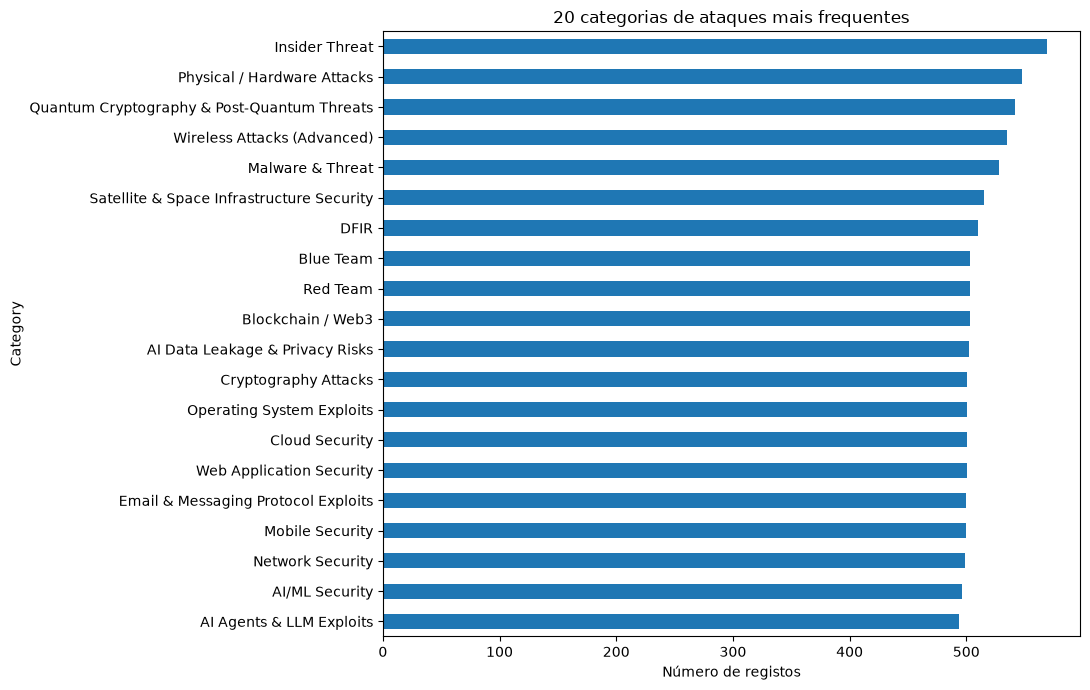

In [3]:
categories = df["Category"].dropna().astype(str).str.strip()
counts = categories[categories != ""].value_counts()
print("Número de categorias:", len(counts))
print("Classes com menos de 100 exemplos:", (counts < 100).sum())
display(counts.head(20).to_frame("Registos"))
counts.head(20).sort_values().plot(kind="barh", figsize=(11, 7))
plt.title("20 categorias de ataques mais frequentes")
plt.xlabel("Número de registos")
plt.tight_layout()
plt.show()


## 4. Comprimento das descrições

Analisamos a dimensão dos textos usados posteriormente na classificação.

,Caracteres
count,14133.000000
mean,127.568740
std,90.933834
min,30.000000
25%,79.000000
50%,103.000000
75%,143.000000
max,795.000000


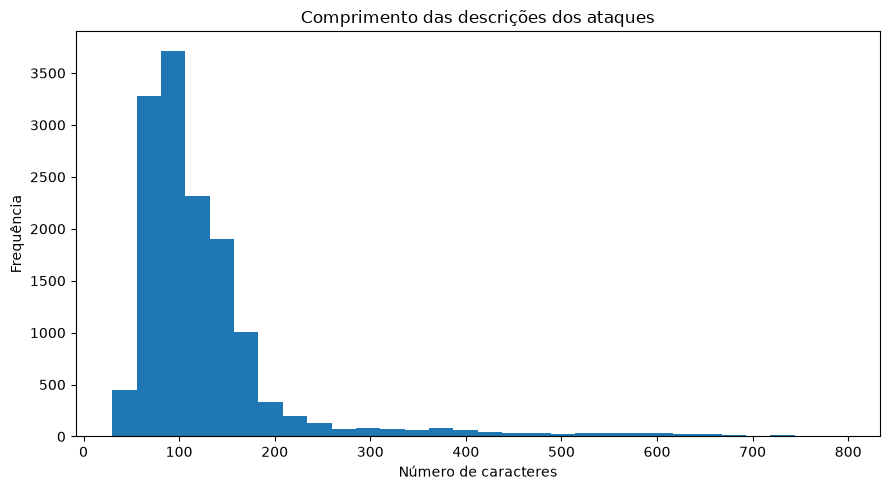

In [4]:
lengths = df["Scenario Description"].fillna("").astype(str).str.len()
display(lengths.describe().to_frame("Caracteres"))
plt.figure(figsize=(9, 5))
plt.hist(lengths, bins=30)
plt.title("Comprimento das descrições dos ataques")
plt.xlabel("Número de caracteres")
plt.ylabel("Frequência")
plt.tight_layout()
plt.show()


## 5. Conclusões

- O dataset original tem **14.133 registos**, **16 colunas** e **64 categorias** (confirmar pelos resultados executados).
- Existem valores em falta e categorias com diferentes números de exemplos.
- Na preparação vamos normalizar os textos, remover duplicados e filtrar classes com menos de 100 amostras.
- O limite de 100 é uma decisão metodológica do projeto.

**Nota:** os 12.891 registos e 27 classes resultam da fase seguinte, Data Preparation.